<a href="https://colab.research.google.com/github/emmaubah/Loan-Approval-Data-Analysis/blob/main/Loan_Approval_Data_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Loan Approval Data Analysis

## Dataset Description

### 🏦 Loan Dataset

This dataset offers information about loan applicants, such as their demographics, financial history, and loan acceptance outcomes. It has 614 rows and 13 columns. The dataset includes both **categorical** and **numerical** variables, it is suitable for applying statistical methods to search for patterns and relationships between applicants' characteristics and loan acceptance decisions. The relationship between loan acceptance and factors including applicant income, loan amount, credit history, education, and work status is the main focus of this investigation.

### Key Features

- **Demographic Information:** Gender, marital status, number of dependents, and education level.

- **Employment and Financial Information:** Self-employment status, applicant income, and co-applicant income.

- **Loan Information:** Requested loan amount, loan repayment term, and credit history.

- **Property Information:** Whether the property is located in an urban, semi-urban, or rural area.

- **Loan Approval Status:** Indicates whether a loan application was approved or rejected. This is the main outcome variable for the analysis.

### 🔍 Column Descriptions

| **Column**  | **Definition** |
|------------|--------------|
| `Loan_ID` | Unique identification number assigned to each loan application. |
| `Gender` | Gender of the loan applicant (Male or Female). |
| `Married` | Indicates whether the applicant is married (Yes or No). |
| **`Dependents**` | Number of people financially dependent on the applicant (0, 1, 2, or 3+). |
| `Education` | Education level of the applicant (Graduate or Not Graduate). |
| **`Self_Employed`** | Indicates whether the applicant is self-employed (Yes or No). |
| **`ApplicantIncome`** | Monthly income earned by the primary loan applicant. |
| `CoapplicantIncome` | Monthly income earned by the co-applicant, if applicable. |
| `LoanAmount` | Amount of money requested for the loan, recorded in thousands. |
| `Loan_Amount_Term` | Duration of the loan repayment period, measured in months. |
| `Credit_History` | Indicates whether the applicant's credit history meets lending guidelines (1 = Yes, 0 = No). |
| `Property_Area` | Location category of the property (Urban, Semiurban, or Rural). |
| `Loan_Status` | Loan application decision (Y = Approved, N = Rejected). |

**Source:** [Kaggle - Loan Dataset](https://www.kaggle.com/datasets/ayushmanyashaswi/loan-dataset-easy-to-understand-yashaswi)


## Data Cleaning and Wrangling



Let's import the libraries and dataset using the following URL. Assign to the variable `loan_approval_df`:

```python
https://raw.githubusercontent.com/emmaubah/Loan-Approval-Data-Analysis/refs/heads/main/data/loan.csv
```

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
import sklearn
from sklearn.metrics import r2_score



In [4]:
url = "https://raw.githubusercontent.com/emmaubah/Loan-Approval-Data-Analysis/refs/heads/main/data/loan.csv"

In [5]:
loan_approval_df = pd.read_csv(url)


Preview the first five loan applications.

In [6]:
loan_approval_df.head(5)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


Check how many rows and columns the dataset has.

In [7]:
# How many rows and columns are in the dataset
loan_approval_df.shape

(614, 13)

The output shows that there are **614 rows and 13 columns**.

From the dataset preview, some columns had missing values. So let's check the count of missing values and how to handle them.

In [8]:
# Check for missing values/ NaN values
loan_approval_df.isnull().sum()

,0
Loan_ID,0
Gender,13
Married,3
Dependents,15
Education,0
Self_Employed,32
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,22
Loan_Amount_Term,14


The output shows that seven columns have missing values: **50** in `Credit_History`, **32** in `Self_Employed`, **22** in `LoanAmount`, and **14** in `Loan_Amount_Term`.

In [9]:
# Check Uniqueness for columns with missing values
# 1. Select the columns correctly using double brackets
missing_values_columns = loan_approval_df[['Gender', 'Married', 'Dependents', 'Self_Employed', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History']]

# 2. View unique values for each of those columns
for col in missing_values_columns.columns:
    print(f"Unique values in {col}: {missing_values_columns[col].unique()}")


Unique values in Gender: ['Male' 'Female' nan]
Unique values in Married: ['No' 'Yes' nan]
Unique values in Dependents: ['0' '1' '2' '3+' nan]
Unique values in Self_Employed: ['No' 'Yes' nan]
Unique values in LoanAmount: [ nan 128.  66. 120. 141. 267.  95. 158. 168. 349.  70. 109. 200. 114.
  17. 125. 100.  76. 133. 115. 104. 315. 116. 112. 151. 191. 122. 110.
  35. 201.  74. 106. 320. 144. 184.  80.  47.  75. 134.  96.  88.  44.
 286.  97. 135. 180.  99. 165. 258. 126. 312. 136. 172.  81. 187. 113.
 176. 130. 111. 167. 265.  50. 210. 175. 131. 188.  25. 137. 160. 225.
 216.  94. 139. 152. 118. 185. 154.  85. 259. 194.  93. 370. 182. 650.
 102. 290.  84. 242. 129.  30. 244. 600. 255.  98. 275. 121.  63. 700.
  87. 101. 495.  67.  73. 260. 108.  58.  48. 164. 170.  83.  90. 166.
 124.  55.  59. 127. 214. 240.  72.  60. 138.  42. 280. 140. 155. 123.
 279. 192. 304. 330. 150. 207. 436.  78.  54.  89. 143. 105. 132. 480.
  56. 159. 300. 376. 117.  71. 490. 173.  46. 228. 308. 236. 570. 380.

Calculate how much data would remain if I used `dropna()` on the dataset.

In [10]:
# Handling missing values by dropping
missing_df = loan_approval_df
missing_df = missing_df.dropna()

print('Rows remaining:', len(missing_df))
print(f"After dropping rows {(len(missing_df)/len(loan_approval_df)) * 100:.2f}% data was retained.")


Rows remaining: 480
After dropping rows 78.18% data was retained.


Decided to maintain valuable records because deleting rows will remove around **22%** of the applications, leaving **480 of 614 rows (78.18%)**.

Let's compute the proportion of missing credit history values to see if it is prevalent in a single `Loan_Status` group.

In [11]:
# The most important column is `Credit_History` for this analysis
# So, to determine whether dropping or filling the ' Credit_History ' rows is common among applicants who are approved or denied

missing_credit = loan_approval_df.groupby('Loan_Status')['Credit_History'].apply(lambda x: x.isna().sum())
missing_percentage = ((missing_credit / loan_approval_df.groupby('Loan_Status').size()) * 100).round(2)

print('Missing Credit_History by loan status (%)')
missing_percentage


Missing Credit_History by loan status (%)


,0
Loan_Status,
N,6.77
Y,8.77


The outcome shows that **6.77%** of rejected applications (`N`) and **8.77%** of accepted applications (`Y`) had missing values. Instead of presuming the missing histories were 0 or 1; I kept the rows because the difference was negligible.

Repeat the same missing-value comparison for `Self_Employed`.

In [12]:
# Another things to conside before dropping or filling:
# percentage loan_status with self_employed
missing_self_employed = loan_approval_df.groupby('Loan_Status')['Self_Employed'].apply(lambda x: x.isna().sum())
missing_self_percentage = (missing_self_employed / loan_approval_df.groupby('Loan_Status').size()) * 100

print('Missing Self_Employed by Loan_Status (%)')
missing_self_percentage

Missing Self_Employed by Loan_Status (%)


,0
Loan_Status,
N,4.687500
Y,5.450237


The output displays a result that is comparable to `Credit_History`. Thus, retain the rows and designate the missing category in `Self_Employed` as `Unknown`.

### Handling missing values

For the duration of the analysis, assign a copy of the original dataset to `cleaned_loan_analysis_df`.

For numerical columns, retain the `NaN` values; for categorical columns, fill in the missing values with `Unknown`.

In [13]:
# Cleaned loan approval dataframe to use for the duration of the analysis
cleaned_loan_approval_df = loan_approval_df.copy()

# After discover and the importance of the colunms 'Credit_History', it will be categorize as: 0,1, and Unknown
# Line of code for filling the 'Credit_Hostory colunm' with 'Unknown' and other catorical colunms
cleaned_loan_approval_df['Credit_History'] = cleaned_loan_approval_df['Credit_History'].fillna("Unknown")
cleaned_loan_approval_df['Self_Employed'] = cleaned_loan_approval_df['Self_Employed'].fillna("Unknown")
cleaned_loan_approval_df['Gender'] = cleaned_loan_approval_df['Gender'].fillna("Unknown")
cleaned_loan_approval_df['Married'] = cleaned_loan_approval_df['Married'].fillna("Unknown")
cleaned_loan_approval_df['Dependents'] = cleaned_loan_approval_df['Dependents'].fillna("Unknown")



After filling categorical columns.

In [14]:
cleaned_loan_approval_df.isnull().sum()

,0
Loan_ID,0
Gender,0
Married,0
Dependents,0
Education,0
Self_Employed,0
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,22
Loan_Amount_Term,14


In [15]:
# Check for duplicate rows in the dataset
cleaned_loan_approval_df.duplicated().sum()

np.int64(0)

Examining the data types and column names, as well as managing the data types of the columns that require modification.

In [16]:
# What are the column names and types in the dataset
display(cleaned_loan_approval_df.columns)

display(cleaned_loan_approval_df.dtypes)

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status'],
      dtype='object')

,0
Loan_ID,object
Gender,object
Married,object
Dependents,object
Education,object
Self_Employed,object
ApplicantIncome,int64
CoapplicantIncome,float64
LoanAmount,float64
Loan_Amount_Term,float64


In [17]:
# Change the appropraite columns data types to differient from
# numerical and categorical colunms for the analysis

cleaned_loan_approval_df = cleaned_loan_approval_df.astype({
    'Loan_ID': 'string',
    'Gender': 'string',
    'Married': 'string',
    'Dependents': 'string',
    'Education': 'string',
    'Self_Employed': 'string',
    'ApplicantIncome': 'float64',
    'Loan_Amount_Term': 'Int64',
    'Credit_History': 'string',
    'Property_Area': 'string',
    'Loan_Status': 'string'
})


In [18]:
# Inspect the data type after the change

display(cleaned_loan_approval_df.dtypes)

,0
Loan_ID,string[python]
Gender,string[python]
Married,string[python]
Dependents,string[python]
Education,string[python]
Self_Employed,string[python]
ApplicantIncome,float64
CoapplicantIncome,float64
LoanAmount,float64
Loan_Amount_Term,Int64


To make the values in the `Dependents` column be simplified, a column called `Has_Dependents` is created. `Dependents`: Indicates whether an applicant has one or more dependents or none.

Remember that from the initial dataset. The missing values in the `Dependents` column were filled in with `Unknown`.

In [19]:
# Filtering the 'Dependent' column: 0 for 'no dependent' & 1,2,& 3+ for 'one or more dependent'
def check_dependents(value):
  value_str = str(value).strip()

  if value_str == 'Unknown':
    return 'Unknown'
  if value_str == '0':
    return 'No Dependents'
  else:
    return 'One or More'

In [20]:
cleaned_loan_approval_df['Has_Dependents'] = cleaned_loan_approval_df['Dependents'].apply(check_dependents)

print(cleaned_loan_approval_df['Has_Dependents'].value_counts())

Has_Dependents
No Dependents    345
One or More      254
Unknown           15
Name: count, dtype: int64


  Also, futher filtering to apply to the cleaned dataframe; is calculating the `TotalIncome` which is the sum of `ApplicantIncome` and `CoapplicantIncome`

In [21]:
# Also will be creating an TotalIncome from ApplicantIncome and CoApplicant to use later on in the
# analysis for a better analysis

cleaned_loan_approval_df['TotalIncome'] = (
    cleaned_loan_approval_df['ApplicantIncome'] +
    cleaned_loan_approval_df['CoapplicantIncome']
)

cleaned_loan_approval_df[['ApplicantIncome', 'CoapplicantIncome', 'TotalIncome']].sample(6)

,ApplicantIncome,CoapplicantIncome,TotalIncome
30,4166.0,3369.0,7535.0
607,3987.0,1411.0,5398.0
466,2947.0,1664.0,4611.0
77,1000.0,3022.0,4022.0
254,16250.0,0.0,16250.0
503,4050.0,5302.0,9352.0


## Measures of Central Tendency and Dispersion



Use `describe()` to examine the count, average, spread, and quartiles of the numerical variables.

In [22]:
# An overview that helps me understand the descriptive statistic of the numerical colunms in the dataset
cleaned_loan_approval_df.describe().round(2)

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,TotalIncome
count,614.00,614.00,592.00,600.0,614.00
mean,5403.46,1621.25,146.41,342.0,7024.71
std,6109.04,2926.25,85.59,65.12,6458.66
min,150.00,0.00,9.00,12.0,1442.00
25%,2877.50,0.00,100.00,360.0,4166.00
50%,3812.50,1188.50,128.00,360.0,5416.50
75%,5795.00,2297.25,168.00,360.0,7521.75
max,81000.00,41667.00,700.00,480.0,81000.00


**Explanation of the output:**

1. The median income of applicants is **3,812.50**, while the average is **5,403.46**. This indicates that **the average may be rising due to a small number of candidates with higher incomes**.
2. The median income of co-applicants is **1,188.50**, while the average is **1,621.25**. **Many applications have no recorded co-applicant income, as seen by the minimum and first quartile both being 0**.
3. The median loan amount is **128.0**, while the average is **146.41**. There are still 22 values missing out of the 592 loan amounts that have been reported.
4. When the maximum values (**81,000 & 41,667**) for the incomes are so extreme, it is possible to conclude that the **mean** of both income variables is affected.**However, the median, offers a more reliable indicator to consider because it is resistant to outliers.**

In [23]:
# an overview of a cateory colunms statical description
cleaned_loan_approval_df.describe(include='string')

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,Credit_History,Property_Area,Loan_Status
count,614,614,614,614,614,614,614,614,614
unique,614,3,3,5,2,3,3,3,2
top,LP001013,Male,Yes,0,Graduate,No,1.0,Semiurban,Y
freq,1,489,398,345,480,500,475,233,422


1. Male applicants (**489**), married applicants (**398**), and graduates (**480**) make up the majority of the dataset. Additionally, **500 candidates** are classified as self-employed.
2. 422 of the 614 applications** were accepted**. With 233 applications, the **most prevalent property area is semiurban**, and the most common **credit history value is 1**.

**What is the difference between accepted and denied loan applications in terms of the averages of `ApplicantIncome`, `CoapplicantIncome`, and `LoanAmount`?**

In [24]:
# Using the central tendency and spread to answer questions about how a loan is approved or rejected with numerical values
# QUESTION 1: How do the average of `applicantINcome`, `coapplicant income`, and `loan amounts` compare between approved and rejected loan applications?

groupby_mean_df = cleaned_loan_approval_df.groupby('Loan_Status')[['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount']].mean().round(2)

groupby_mean_df


,ApplicantIncome,CoapplicantIncome,LoanAmount
Loan_Status,,,
N,5446.08,1877.81,151.22
Y,5384.07,1504.52,144.29


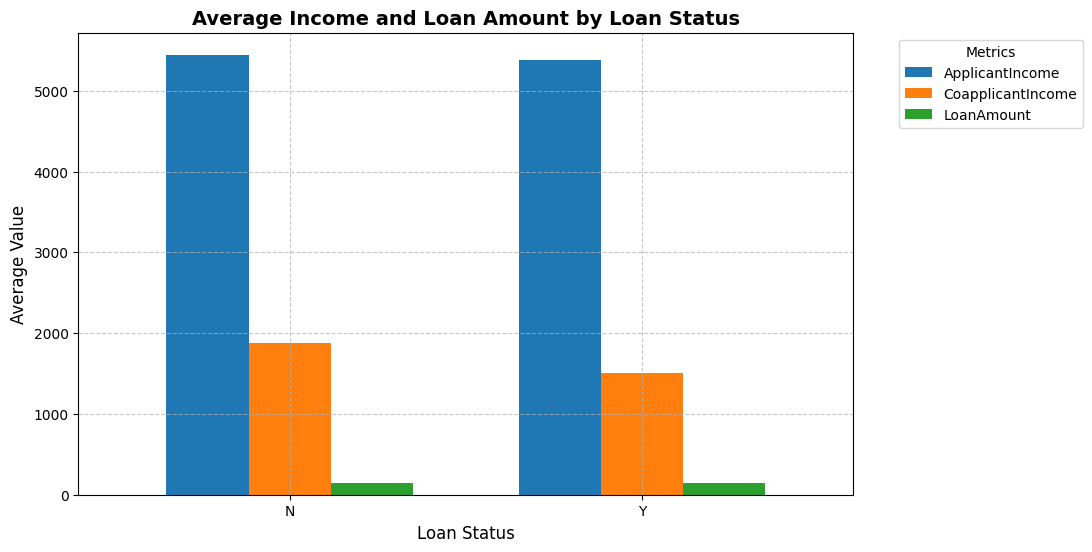

In [25]:

groupby_mean_df.plot(kind='bar',
                       figsize=(10, 6),
                       width=0.7)

plt.title('Average Income and Loan Amount by Loan Status',
          fontsize=14,
          fontweight='bold')

plt.xlabel('Loan Status', fontsize=12)
plt.ylabel('Average Value', fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='both', linestyle='--', alpha=0.7)
plt.legend(title='Metrics', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.show()


The average income of rejected candidates was **somewhat greater (5,446.08) than** that of **approved applicants (5,384.07)**. Additionally, their requested loan amounts and average co-applicant salaries were greater. The disparities do not, however, **imply that rejection is a direct result of earning more money**.

**What is the difference between the median and mean earnings of applicants?**

In [26]:
# QUESTION 2: How does the mean and median applicant income compare to loan approval & rejected applicants?
# OPTIONAL: reveal the income differences about the dist. with each group(y or n)

income_mean_median = cleaned_loan_approval_df.groupby('Loan_Status')['ApplicantIncome'].agg(['mean', 'median']).round(2)

income_mean_median

# This demo shows that the applicant income average is higher for the applicant who got rejected, while the median
# shows a more acceptable metric of rejection based on the result becauese an extreme applicant income value could
# suede the results a bit while median checks for the middle income


,mean,median
Loan_Status,,
N,5446.08,3833.5
Y,5384.07,3812.5


  An illustration of the table result in a distribution using the function `subplot()` for side-by-side comparison

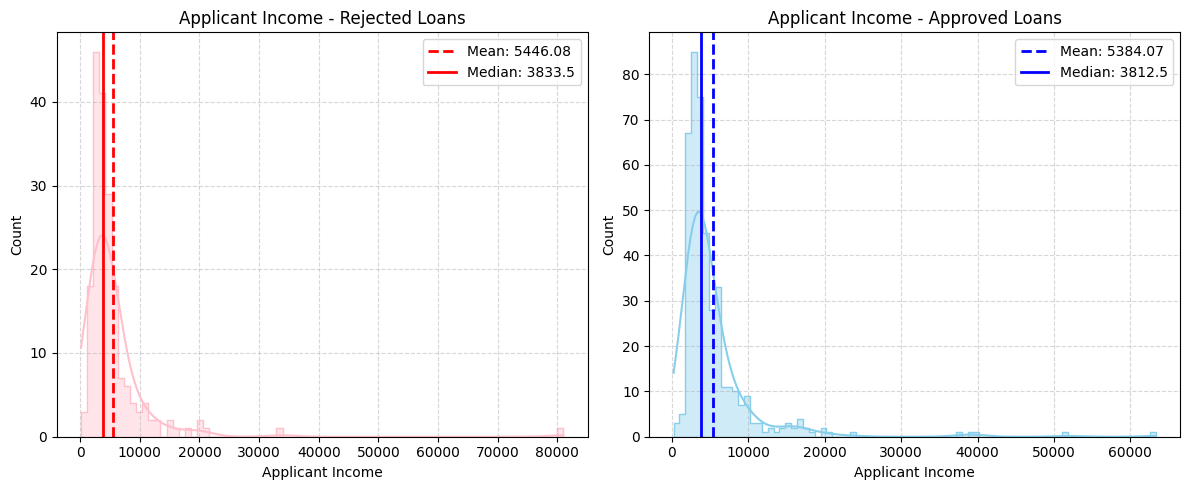

In [27]:

# Creating a figure with two subplots (1 row, 2 columns)
plt.figure(figsize=(12, 5))

# First Plot: Applicant Income for Rejected Loans
plt.subplot(1, 2, 1)

sns.histplot(
    data=cleaned_loan_approval_df[
        cleaned_loan_approval_df["Loan_Status"] == "N"
    ],
    x="ApplicantIncome",
    color="pink",
    element="step",
    kde=True,
    alpha=0.4
)

# Mean line (Dashed)
plt.axvline(
    x=income_mean_median.loc["N", "mean"],
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {income_mean_median.loc['N', 'mean']}"
)

# Median line (Solid)
plt.axvline(
    x=income_mean_median.loc["N", "median"],
    color="red",
    linestyle="-",
    linewidth=2,
    label=f"Median: {income_mean_median.loc['N', 'median']}"
)

plt.xlabel("Applicant Income")
plt.ylabel("Count")
plt.title("Applicant Income - Rejected Loans")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)


# Second Plot: Applicant Income for Approved Loans
plt.subplot(1, 2, 2)

sns.histplot(
    data=cleaned_loan_approval_df[
        cleaned_loan_approval_df["Loan_Status"] == "Y"
    ],
    x="ApplicantIncome",
    color="skyblue",
    element="step",
    kde=True,
    alpha=0.4
)

# Mean line (Dashed)
plt.axvline(
    x=income_mean_median.loc["Y", "mean"],
    color="blue",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {income_mean_median.loc['Y', 'mean']}"
)

# Median line (Solid)
plt.axvline(
    x=income_mean_median.loc["Y", "median"],
    color="blue",
    linestyle="-",
    linewidth=2,
    label=f"Median: {income_mean_median.loc['Y', 'median']}"
)

plt.xlabel("Applicant Income")
plt.ylabel("Count")
plt.title("Applicant Income - Approved Loans")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

# Adjust layout and show the plots
plt.tight_layout()
plt.show()


The income distributions of both accepted and rejected candidates are **tilted to the right**, with a few **exceptionally high incomes**. In both groups, the mean is greater than the median, indicating that the **averages are impacted by extreme values**. For those who get accepted, the **median wages are quite similar**.

**What is spread in the overall income distribution by status?**

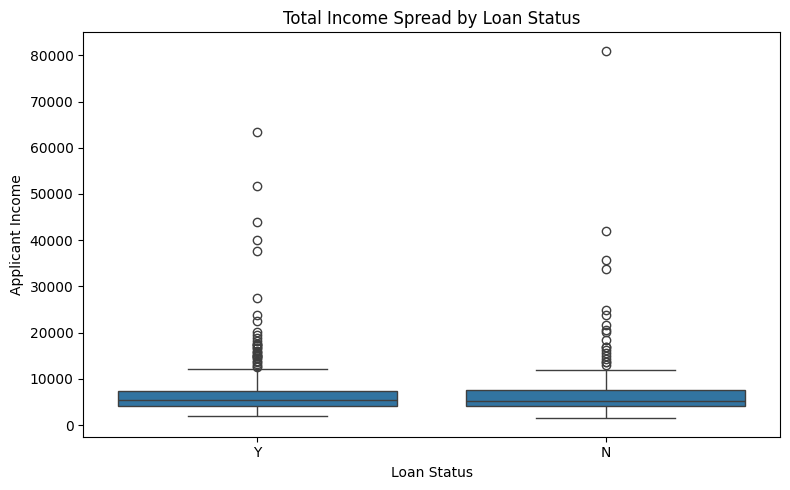

In [28]:
# QUESTION 3:

plt.figure(figsize=(8,5))
sns.boxplot(data=cleaned_loan_approval_df, x='Loan_Status', y='TotalIncome')
plt.title('Total Income Spread by Loan Status')
plt.xlabel('Loan Status')
plt.ylabel('Applicant Income')
plt.tight_layout()
plt.show()


The box plot demonstrates how the middle ranges of total income for applications that were accepted and those that were denied are quite comparable. There are a few high-income outliers in both categories, but the rejected group's values are very high. **The total distribution is far wider than the major boxes indicate because of these outliers.**

**What is the median married applicant's loan status depending on their dependents?**

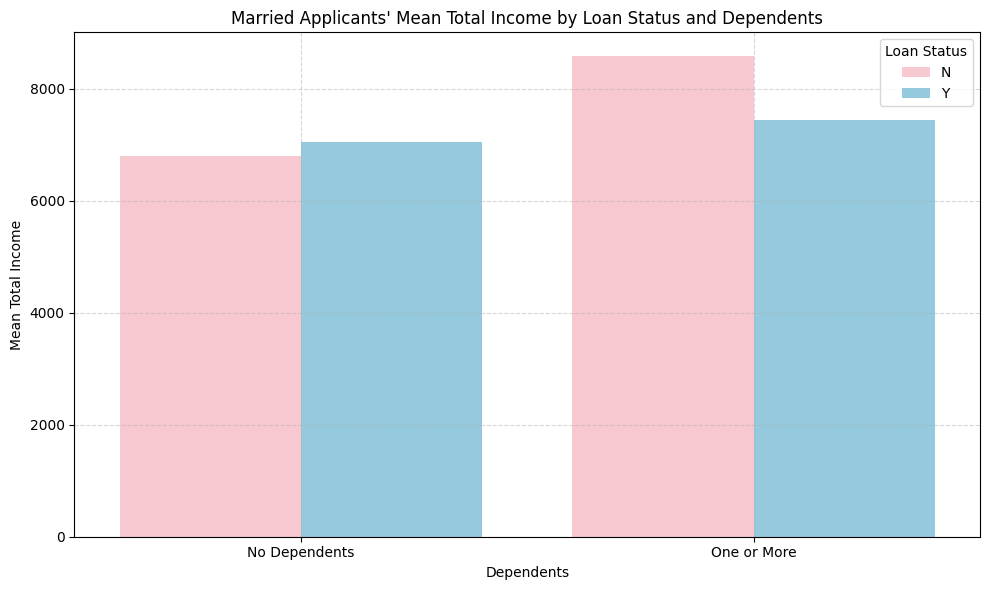

In [29]:
# QUESTION 5:

married_df = cleaned_loan_approval_df[
    (cleaned_loan_approval_df["Married"] == "Yes") &
    (cleaned_loan_approval_df["Has_Dependents"] != "Unknown")
].copy()

# Calculate mean total income by dependents and loan status
mean_income = married_df.groupby(
    ["Has_Dependents", "Loan_Status"],
    observed=True
)["TotalIncome"].mean().round(2)

# Create a grouped bar plot
plt.figure(figsize=(10, 6))

sns.barplot(
    data=married_df,
    x="Has_Dependents",
    y="TotalIncome",
    hue="Loan_Status",
    order=["No Dependents", "One or More"],
    hue_order=["N", "Y"],
    palette={"N": "pink", "Y": "skyblue"},
    errorbar=None
)

plt.title("Married Applicants' Mean Total Income by Loan Status and Dependents")
plt.xlabel("Dependents")
plt.ylabel("Mean Total Income")
plt.legend(title="Loan Status")
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


The accepted group's average total income **is somewhat greater among married candidates without dependents**. The rejected group's average total income **is higher for applicants who have one or more dependents**.

**How does an application vary based on the number of dependents and overall income?**

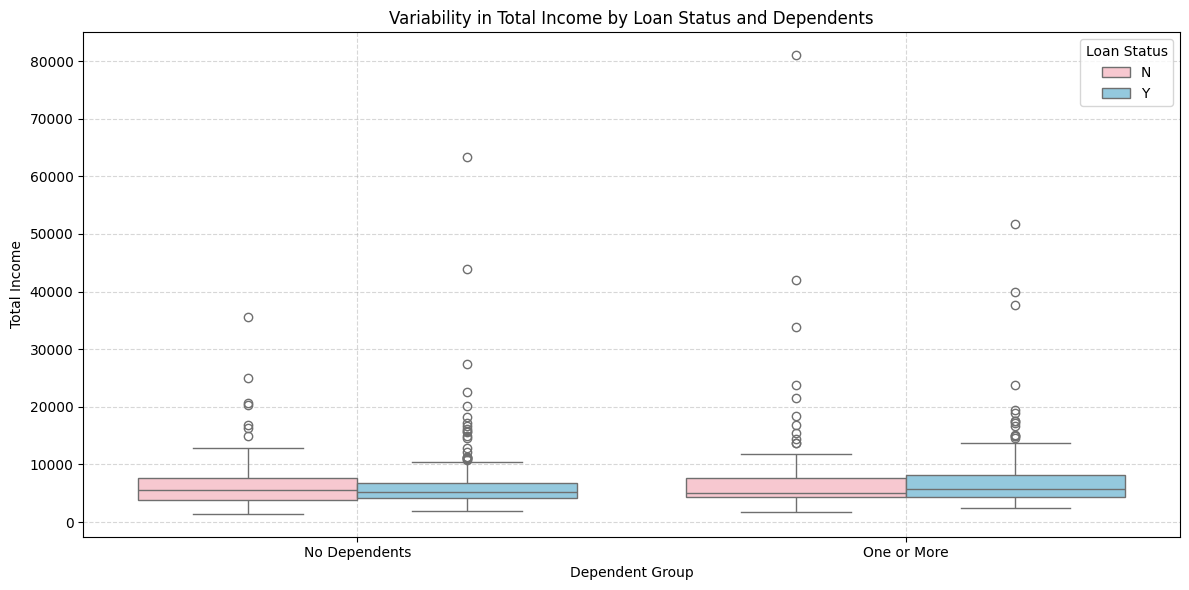

In [30]:
# QUESTION 4:

dependents_df = cleaned_loan_approval_df[
    cleaned_loan_approval_df["Has_Dependents"] != "Unknown"
].copy()

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=dependents_df,
    x="Has_Dependents",
    y="TotalIncome",
    hue="Loan_Status",
    order=["No Dependents", "One or More"],
    hue_order=["N", "Y"],
    palette={"N": "pink", "Y": "skyblue"}
)

plt.title("Variability in Total Income by Loan Status and Dependents")
plt.xlabel("Dependent Group")
plt.ylabel("Total Income")
plt.legend(title="Loan Status")
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()



The box plots depict variations in the distribution of total income among the dependent groups and the results of loan approval. Each group features some high-income outliers, but the majority of observations are centered in lower-income groups. **Having dependents by itself does not distinguish between applications that are accepted and those that are refused since the income distributions overlap.**

### Visualization


To see how the number columns are distributed, let's make a **pair plot**.

<Figure size 1200x900 with 0 Axes>

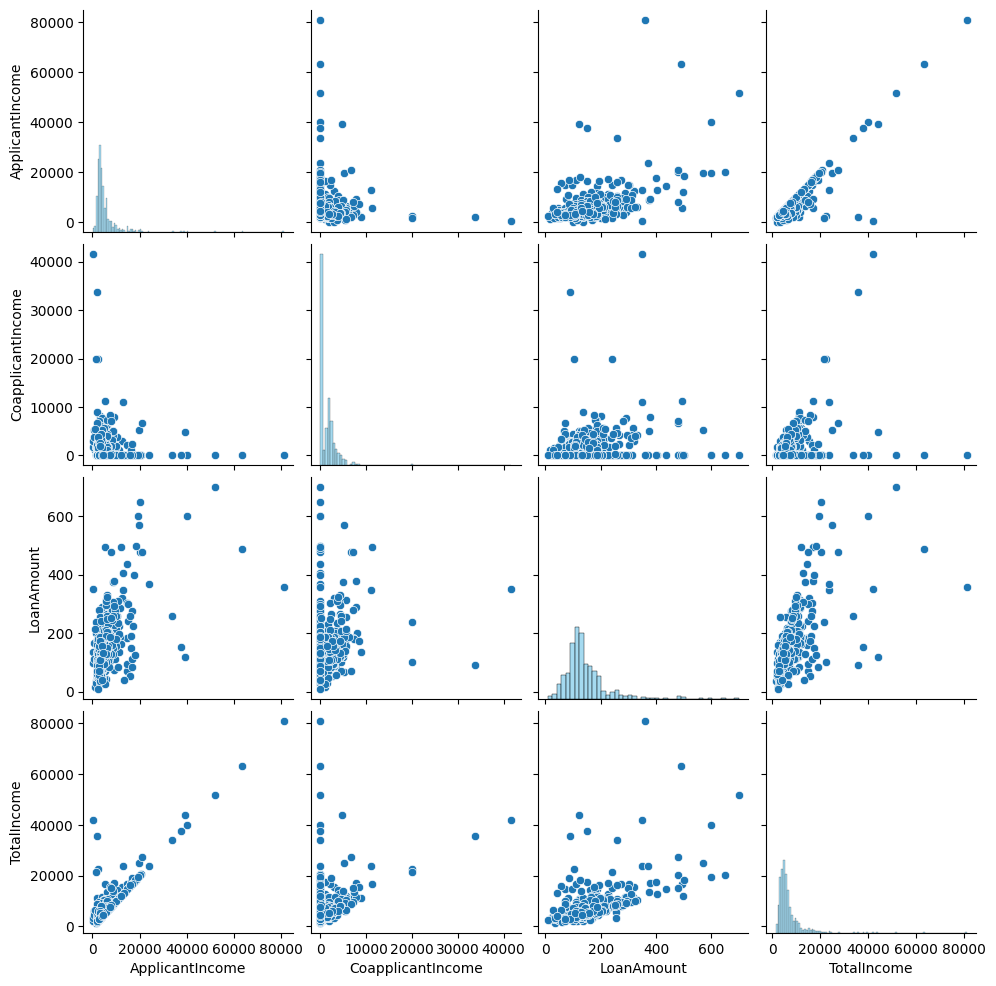

In [31]:
# Let's make a pairplot for numerical columns to look for correlations that will be utilized later
# and to pose and respond to queries based on the outcomes of different groups using a pair plot

pairplot_df = cleaned_loan_approval_df.copy()

numerical_columns = ['ApplicantIncome', 'CoapplicantIncome','LoanAmount','TotalIncome']

plt.figure(figsize=(12, 9))
sns.pairplot(pairplot_df[numerical_columns],
             diag_kind='hist',
             diag_kws={'color': 'skyblue'})
plt.show()

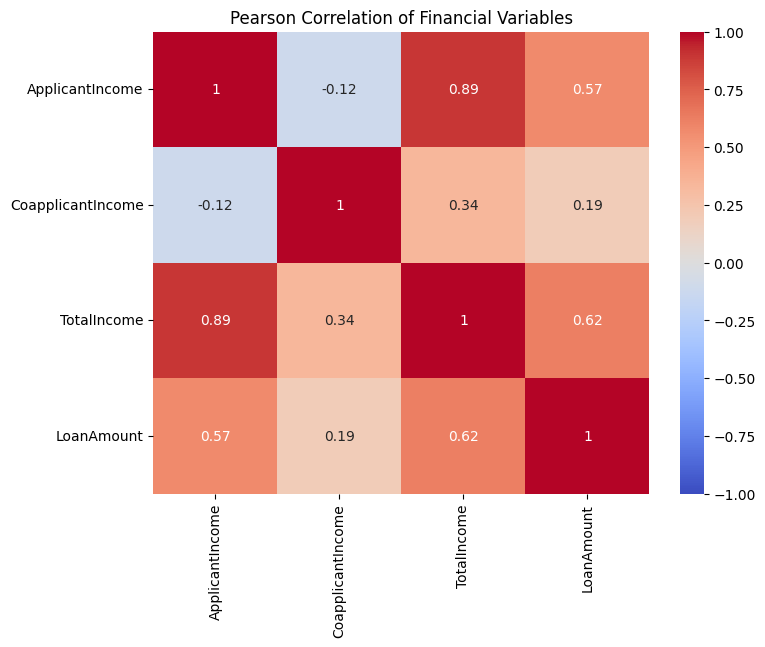

In [32]:
# Pearson correlation
correlation = pairplot_df[
    ['ApplicantIncome', 'CoapplicantIncome',
     'TotalIncome', 'LoanAmount']
].corr(method='pearson')

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0
)

plt.title('Pearson Correlation of Financial Variables')
plt.show()


According to the Pearson heatmap results, the applicant's income vs. loan amount is approximately `0.57`, and the total income versus loan amount is approximately `0.62`. In contrast, there was a lower correlation between the loan amount and the variable output of co-applicant income (`0.19`).

To learn more about `CoapplicantIncome`, Pearson's r raises the following query: **Could the comparison be impacted by zero co-applicant incomes?**

In [33]:
def categorize_income(income):
    if income > 0:
        return "Positive Coapplicant Income"
    else:
        return "Zero Coapplicant Income"


pairplot_df["Coapplicant_Group"] = pairplot_df["CoapplicantIncome"].apply(
    categorize_income
)

pairplot_df['Coapplicant_Group'].value_counts()


,count
Coapplicant_Group,
Positive Coapplicant Income,341
Zero Coapplicant Income,273


While the table only displays the number of zeros and non-zeros in co-applicant income, a **regression line visualization** is used to compare the applicant income with and without zeros to determine whether zeros have an impact.

**What is the relationship between the applicant's and co-applicant's incomes?**

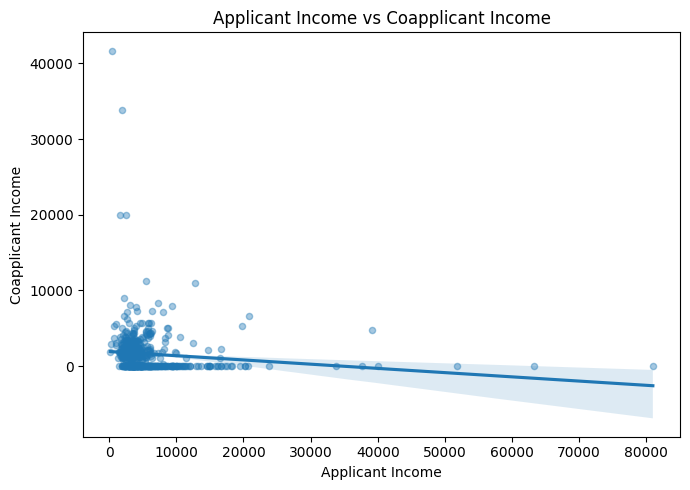

In [34]:
# Examine the link between applicant income and co-applicant income using a scatter plot with a regression
# line. This raises the issue of the poor linear correlation between the two variables.

plt.figure(figsize=(7, 5))
sns.regplot(
    data=pairplot_df,
    x='ApplicantIncome', y='CoapplicantIncome',
    scatter_kws={'alpha': 0.4, 's': 20}
)
plt.title('Applicant Income vs Coapplicant Income')
plt.xlabel('Applicant Income')
plt.ylabel('Coapplicant Income')

plt.tight_layout()
plt.show()



**Since values are clustered close to zero, the scatter plot displays a weak decreasing trend** between applicant income and co-applicant income.

**Does a co-applicant's positive income affect the income relationship?**

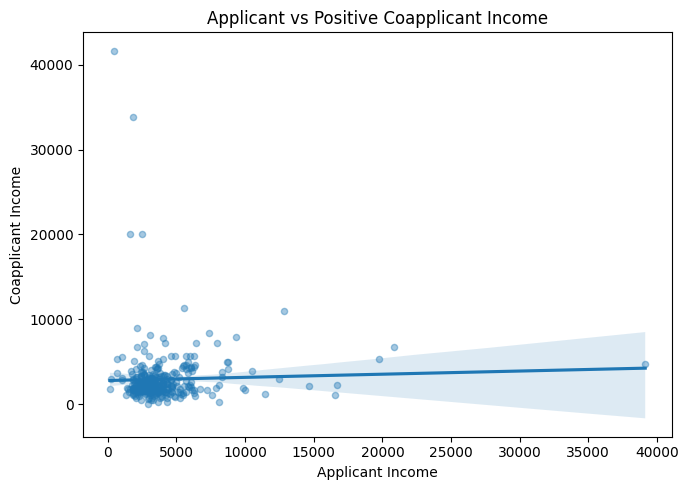

In [35]:
positive_coapplicant_df = pairplot_df[
    pairplot_df['CoapplicantIncome'] > 0
]

plt.figure(figsize=(7, 5))
sns.regplot(
    data=positive_coapplicant_df,
    x='ApplicantIncome', y='CoapplicantIncome',
    scatter_kws={'alpha': 0.4, 's': 20}
)
plt.title('Applicant vs Positive Coapplicant Income')
plt.xlabel('Applicant Income')
plt.ylabel('Coapplicant Income')
plt.tight_layout()
plt.show()

Overall, the co-applicant income visualizations demonstrate that when co-applicant incomes are positive, the line's trend shifts higher. The line shows a tiny increase. **Indicating that the next inquiry should utilize a combination to prevent any discrepancy in correlation.**

### ScatterPlot

In this section, we will:
- **Fit a linear regression model** using `scikit-learn`.  
- **Visualize the regression line** along with the data points using a scatter plot.
- **Explore metrics for linear regression** like coefficient of correlation and coefficient of determination.

**Justification for the Correlation's use of the `TotalIncome` variable**

Combine these earnings to account for them collectively rather than use both components of the primary income variables (`ApplicantIncome` \& `CoapplicantIncome`). Remember that the value in `CoapplicantIncome` is `0`.

In [36]:
pct_coapp_zero = (cleaned_loan_approval_df['CoapplicantIncome'] == 0).mean() * 100

print(f"The Percentage of Zeros in Coapplicant is: {pct_coapp_zero:.2f}%")

The Percentage of Zeros in Coapplicant is: 44.46%


It is reasonable to combine both variables and utilize them for the regression analysis because the `Coapplicant` column has `44.46%` zeros.

**What connection exists between the proposed loan amount and total income?**

To find out if applicants with greater total income typically ask for larger loans, **I'll apply a linear regression equation**. This relationship will be described in part by the slope and intercept.

In [37]:
# The loan amount and the total income appear to be roughly positively correlated in this scatter.
# Based on the correlation, create a scatterplot using a least-squares regression line,
# and use the regression equation to predict the y-value.
# Find the r values using the domain and the loan amount approved by the applicant.


regression_df = cleaned_loan_approval_df[
    ['TotalIncome', 'LoanAmount']
].dropna()

slope, intercept = np.polyfit(
    regression_df['TotalIncome'], regression_df['LoanAmount'], 1
)

print(f'Predicted LoanAmount = {slope:.5f} * TotalIncome + {intercept:.2f}')


Predicted LoanAmount = 0.00819 * TotalIncome + 88.72


The approximate regression equation is:

`Estimated Loan Amount = 0.00819 x Total Income + 88.72`

The dataset's positive slope indicates that higher total income is linked to larger loan requests.

Intercept (β₀): 88.72
Slope (β₁): 0.01
Correlation Coefficient (r): 0.62


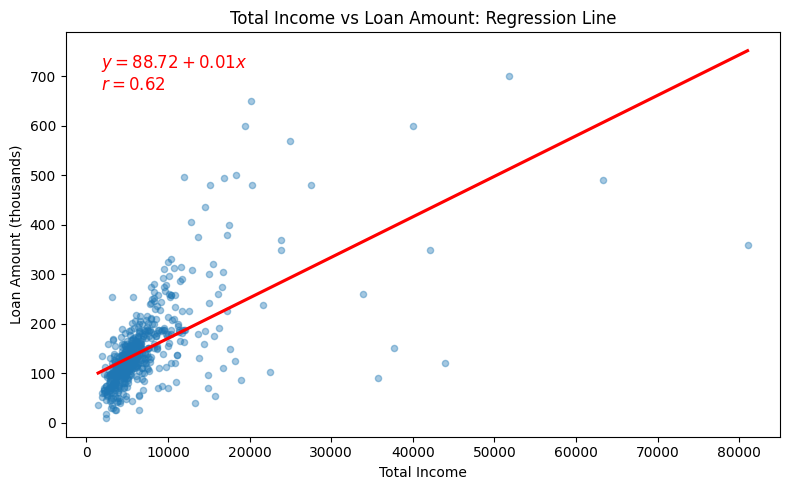

In [38]:

# Convert ApplicantIncome and LoanAmount to numpy arrays
X = regression_df['TotalIncome'].to_numpy().reshape(-1, 1)
y = regression_df['LoanAmount'].to_numpy()

# Fit the linear regression model
lin_reg = LinearRegression()
lin_reg.fit(X, y)

# Extract coefficients
beta_0 = lin_reg.intercept_
beta_1 = lin_reg.coef_[0]
print(f"Intercept (β₀): {beta_0:.2f}")
print(f"Slope (β₁): {beta_1:.2f}")

# Calculate the correlation coefficient (r)
# np.corrcoef returns a matrix; [0, 1] extracts the correlation between X and y
correlation_matrix = np.corrcoef(regression_df['TotalIncome'], y)
r_value = correlation_matrix[0, 1]
print(f"Correlation Coefficient (r): {r_value:.2f}")

# Create the plot
plt.figure(figsize=(8, 5))
sns.regplot(
    data=regression_df,
    x='TotalIncome',
    y='LoanAmount',
    scatter_kws={'alpha': 0.4, 's': 20},
    line_kws={'color': 'red'},
    ci=None
)

# Create the equation and correlation text, then annotate the plot
equation_text = f"$y = {beta_0:.2f} + {beta_1:.2f}x$\n$r = {r_value:.2f}$"
plt.text(0.05, 0.95, equation_text, transform=plt.gca().transAxes, fontsize=12, color="red", verticalalignment='top')

plt.title('Total Income vs Loan Amount: Regression Line')
plt.xlabel('Total Income')
plt.ylabel('Loan Amount (thousands)')
plt.tight_layout()
plt.show()



**Total income and loan amount are positively correlated**, according to the regression diagram. A moderately positive association is indicated by the correlation coefficient, **which is roughly 0.62**. However, **as the observations are dispersed, not all variations in loan amounts can be explained by total income.**

**For a normal income, what loan amount does the line predict?**

In [39]:
def ols_equations(value):
    y_new = beta_0 + beta_1 * value
    return y_new.round(2)

x_new_1 = regression_df['TotalIncome'].median()
x_new_2 = regression_df['TotalIncome'].mean()

print(f"Prediction for the first loan amount: {ols_equations(x_new_1)} (thousands)\nPrediction for the second loan amount: {ols_equations(x_new_2)} (thousands)")

Prediction for the first loan amount: 132.99 (thousands)
Prediction for the second loan amount: 146.41 (thousands)


The `r2_score` function allows us to compute $ R^2$ and $ R$. to determine the linearity between the desired loan amount and overall revenue.

In [40]:
# we can calculate the Pearson correlation coefficient directly.
# np.corrcoef returns the correlation matrix; the off-diagonal element [0,1] is the correlation coefficient.
corr = np.corrcoef(X.flatten(), y)[0, 1]
r2_direct = corr**2

print(f"Correlation Coefficient (r): {corr:.3f}")
print(f"Coefficient of Determination (R²): {r2_direct:.3f}")

Correlation Coefficient (r): 0.625
Coefficient of Determination (R²): 0.390


The coefficient of determination is **0.390**, and the correlation value is **0.625**. This indicates that, using total income, **the linear regression model accounts for about 39% of the variation in loan amounts requested.**

### Probability


**What is the likelihood that an application chosen at random would be accepted?**

In [41]:
# The answers to the following questions will be determined at random in this section:
# Given random selection, what is the likelihood that their loan will be accepted in relation
# to the total number of applicants and the likelihood that it will be rejected?

loan_counts = cleaned_loan_approval_df['Loan_Status'].value_counts()

prob_approved = loan_counts['Y'] / len(cleaned_loan_approval_df)
prob_rejected = loan_counts['N'] / len(cleaned_loan_approval_df)

print(f'The Probability of being Approved: {prob_approved:.2%}')
print(f'The Probabilty of being Rejected: {prob_rejected:.2%}')

The Probability of being Approved: 68.73%
The Probabilty of being Rejected: 31.27%


A randomly chosen application has **a 68.73% chance of being accepted** and a 31.27% chance of being rejected. This **indicates that the majority of this dataset consists of accepted applications.**

**How does credit history affect the likelihood of approval?**

In [42]:
# That a applicant's credit score was 1, meeting the guideline.
# When they were given the loan, they had no credit history, which suggested that they lacked credibility.


known_credit_df = cleaned_loan_approval_df[
    cleaned_loan_approval_df["Credit_History"].isin(["0.0", "1.0"])
]

credit_approval = pd.crosstab(
    known_credit_df["Credit_History"],
    known_credit_df["Loan_Status"],
    normalize="index"
) * 100

display(credit_approval.round(2))



Loan_Status,N,Y
Credit_History,,
0.0,92.13,7.87
1.0,20.42,79.58


An applicant with a credit history of 1 is more likely to be granted for a loan (**79.58%**) than one with a credit history of 0, according to the output; hence, **a considerable correlation has been found between credit history and loan acceptance.**

**How does the likelihood of approval vary by property area?**

In [43]:
# The likelihood of a loan being accepted varies depending on the applicants' property areas,
# which could result in a high or low observed approval proportion.

property_approval = pd.crosstab(
    cleaned_loan_approval_df['Property_Area'],
    cleaned_loan_approval_df['Loan_Status'],
    normalize='index'
) * 100

print('Loan status percentages by property area:')
display(property_approval.round(2))

Loan status percentages by property area:


Loan_Status,N,Y
Property_Area,,
Rural,38.55,61.45
Semiurban,23.18,76.82
Urban,34.16,65.84


**At 76.82%, semiurban areas have the highest loan approval rate**, followed by urban areas at 65.84% and rural areas at 61.45%. This helps **answer conditional probability queries about a region** by indicating that approval rates vary by property area in this dataset.

**Are applicants with incomes of $5,000 or less more likely to be turned down?**

In [44]:
# Lastly, in light of the applicant income groups of $5,000 or less, to identify the problem.
# What is the link if the application from the higher-income class was rejected?

cleaned_loan_approval_df['Income_Group'] = 'Above 5000'
cleaned_loan_approval_df.loc[
    cleaned_loan_approval_df['TotalIncome'] <= 5000,
    'Income_Group'
] = '5000 or Below'

income_approval = pd.crosstab(
    cleaned_loan_approval_df['Income_Group'],
    cleaned_loan_approval_df['Loan_Status'],
    normalize='index'
) * 100

print('Loan status percentages by applicant income group:')
display(income_approval.round(2))


Loan status percentages by applicant income group:


Loan_Status,N,Y
Income_Group,,
5000 or Below,32.96,67.04
Above 5000,29.94,70.06


**Rejection rates are 32.96%** for applications with a total income of $5,000 or less and **29.94% for those with more than $5,000**. The difference, which is roughly 3 percentage points, indicates that the **lower-income group in this dataset had a marginally higher rejection rate.**




 ### Additional Assessment


This graphic illustrates the relationship between **loan approval and an applicant's credit history**.

<function matplotlib.pyplot.show(close=None, block=None)>

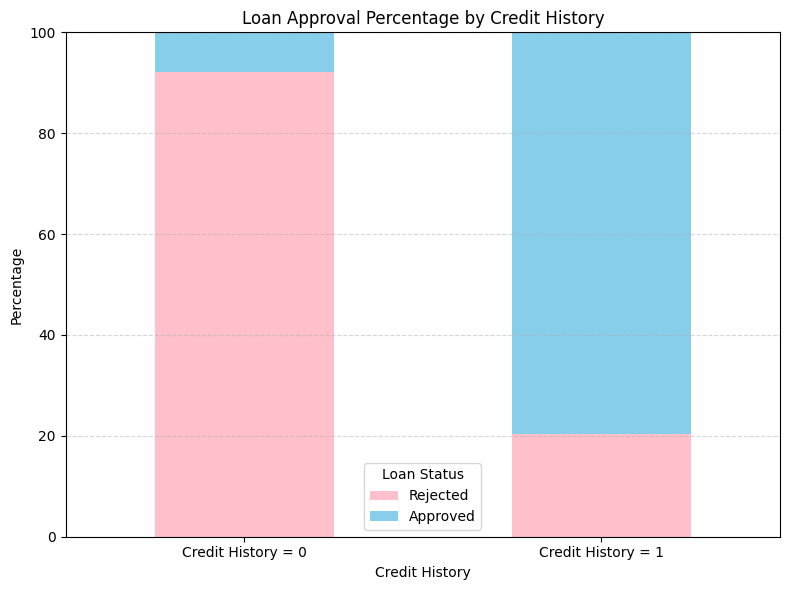

In [46]:
credit_approval.index = ["Credit History = 0", "Credit History = 1"]
credit_approval.columns = ["Rejected", "Approved"]

credit_approval.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 6),
    color=["pink", "skyblue"]
)

plt.title("Loan Approval Percentage by Credit History")
plt.xlabel("Credit History")
plt.ylabel("Percentage")
plt.legend(title="Loan Status")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.5)


plt.tight_layout()
plt.show



### Conclusion

- The `loan.csv` dataset was cleaned, examined, and turned into a cleaned dataset that was utilized for probability calculations, linear regression, descriptive statistics, and visualizations regarding the necessity of loan approval or denial.
- The objective of this loan approval analysis research was to determine which factors are unnecessary and to comprehend the relationship between applicants' financial and personal information and loan acceptance choices.
- We concluded the loan analysis by combining the two main financial income variables, `ApplicantIncome` & `CoapplicantIncome`, into a `TotalIncome` variable. We discovered that total income has a positive relationship with the requested loan amounts for an applicant, while the likelihood of an applicant with a good credit history shows a strong association with loan approval.
